<a href="https://colab.research.google.com/github/Minh-Quan-hub/build-ai-agents-and-chatbots-118s/blob/AgenticAI_in_Marketing/ad_optimization_agent_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **1. Ad Optimization Agent**

In [25]:
SYSTEM_PROMPT = """You review daily ad-budget shifts to improve conversions across Search, Social, and Display.
The host supplies the proposed budget shift and conversions per dollar from the previous three completed days.
Explain why the receiving channel earned more budget in at most 18 words. Focus on conversion efficiency.
Do not invent metrics, change dollar amounts, include customer information, or write ad copy.
The budget tool enforces the fixed daily total, 10% minimum channel share, 20% daily change limit, and 10% transfer limit.
"""

### **2. Setup and CSV Upload**

In [26]:
%pip -q install langgraph openai

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from typing import TypedDict
from pydantic import BaseModel
from openai import OpenAI
from langgraph.graph import StateGraph, END
from google.colab import files, userdata

DAILY_BUDGET = 300.0
USE_LLM = True
MODEL = "gpt-4o-mini"

uploaded = files.upload()
data = pd.read_csv(next(iter(uploaded)), parse_dates=["date"]).sort_values(["date", "channel"])
channels = tuple(sorted(data["channel"].unique()))
client = OpenAI(api_key=userdata.get("OPENAI_API_KEY")) if USE_LLM else None
print(f"Loaded {len(data)} rows for {len(channels)} channels and {data.date.nunique()} days.")

Saving ad_performance_mock.csv to ad_performance_mock (2).csv
Loaded 63 rows for 3 channels and 21 days.


### **3. Performance Metrics and Budget Tool**

In [27]:
def calculate_metrics(rows):
    totals = rows.groupby("channel")[["spend", "impressions", "clicks", "conversions"]].sum()
    totals["ctr"] = totals.clicks / totals.impressions.replace(0, np.nan)
    totals["cvr"] = totals.conversions / totals.clicks.replace(0, np.nan)
    totals["cpa"] = totals.spend / totals.conversions.replace(0, np.nan)
    totals["conversions_per_dollar"] = totals.conversions / totals.spend
    return totals


def decide_budget_shift(previous, recent):
    rates = calculate_metrics(recent)["conversions_per_dollar"]
    winner = rates.idxmax()
    proposed = previous.copy()
    reason = "Hold: recent performance does not support an eligible shift."

    for donor in rates.sort_values().index:
        if donor == winner or rates[winner] <= 1.05 * rates[donor]:
            continue
        amount = round(min(0.10 * DAILY_BUDGET, 0.20 * previous[winner],
                           0.20 * previous[donor], previous[donor] - 0.10 * DAILY_BUDGET), 2)
        if amount > 0:
            proposed[winner] = round(previous[winner] + amount, 2)
            proposed[donor] = round(previous[donor] - amount, 2)
            reason = (f"Move ${amount:.2f} from {donor} to {winner}: "
                      f"recent conversions/$ {rates[winner]:.4f} vs {rates[donor]:.4f}.")
            break
    return proposed, reason

### **4. LangGraph Agent and Daily Decisions**

In [28]:
class AgentState(TypedDict, total=False):
    date: pd.Timestamp
    day_number: int
    previous: dict
    recent: pd.DataFrame
    budget: dict
    reason: str


class BudgetReview(BaseModel):
    reason: str


def fetch_campaign_data(state: AgentState):
    prior = data[data.date < state["date"]]
    recent_days = sorted(prior.date.unique())[-3:]
    return {"recent": prior[prior.date.isin(recent_days)]}


def agent_reasoning(state: AgentState):
    if state["day_number"] < 3:
        return {"budget": state["previous"], "reason": "Equal-split learning period."}

    proposed, reason = decide_budget_shift(state["previous"], state["recent"])
    if USE_LLM and proposed != state["previous"]:
        rates = calculate_metrics(state["recent"])["conversions_per_dollar"].round(4).to_dict()
        response = client.responses.parse(
            model=MODEL,
            input=[{"role": "system", "content": SYSTEM_PROMPT},
                   {"role": "user", "content": json.dumps({"date": str(state["date"].date()),
                    "move": reason.split(":")[0], "conversions_per_dollar": rates})}],
            text_format=BudgetReview,
            max_output_tokens=120,
            store=False,
        )
        reason += " API explanation: " + response.output_parsed.reason
    return {"budget": proposed, "reason": reason}


def execute_tools(state: AgentState):
    return {"budget": state["budget"]}  # Simulated allocation; no ad-platform write.


workflow = StateGraph(AgentState)
workflow.add_node("fetch_campaign_data", fetch_campaign_data)
workflow.add_node("agent_reasoning", agent_reasoning)
workflow.add_node("execute_tools", execute_tools)
workflow.set_entry_point("fetch_campaign_data")
workflow.add_edge("fetch_campaign_data", "agent_reasoning")
workflow.add_edge("agent_reasoning", "execute_tools")
workflow.add_edge("execute_tools", END)
app = workflow.compile()

previous = {channel: round(DAILY_BUDGET / len(channels), 2) for channel in channels}
previous[channels[-1]] = round(DAILY_BUDGET - sum(previous[ch] for ch in channels[:-1]), 2)
log = []
for day_number, date in enumerate(sorted(data.date.unique())):
    result = app.invoke({"date": pd.Timestamp(date), "day_number": day_number, "previous": previous})
    current = result["budget"]
    for channel in channels:
        log.append({"date": date, "channel": channel,
                    "previous_budget": previous[channel], "budget": current[channel],
                    "shift": round(current[channel] - previous[channel], 2), "reason": result["reason"]})
    previous = current

decisions = pd.DataFrame(log)
from IPython.display import display, Markdown

budget_table = decisions.pivot(index="date", columns="channel", values="budget")
budget_table = budget_table.reindex(columns=["Search", "Social", "Display"])
budget_table["Total"] = budget_table.sum(axis=1)
budget_table.index = budget_table.index.strftime("%Y-%m-%d")
budget_table.index.name = "Date"
display(Markdown("### Daily budgets by channel (USD)"))
display(budget_table.round(2))

change_rows = []
for date, group in decisions.groupby("date"):
    gained = group[group["shift"] > 0]
    if gained.empty:
        continue
    winner = gained.iloc[0]
    donor = group.loc[group["shift"] < 0, "channel"].iloc[0]
    rule, _, agent_note = winner["reason"].partition(" API explanation: ")
    if len(agent_note.split()) > 18:
        agent_note = f"{winner['channel']} had higher recent conversions per dollar than {donor}."
    change_rows.append({
        "Date": date.strftime("%Y-%m-%d"),
        "Budget shift": f"{donor} → {winner['channel']} (${winner['shift']:.2f})",
        "Recent conversions/$": rule.split("recent conversions/$ ")[1].rstrip("."),
        "Short explanation": agent_note or "Higher recent conversions per dollar.",
    })

changes = pd.DataFrame(change_rows)
display(Markdown(f"### Budget shifts ({len(changes)} across {len(budget_table)} days)"))
with pd.option_context("display.max_colwidth", None):
    display(changes)

### Daily budgets by channel (USD)

channel,Search,Social,Display,Total
Date,,,,
2026-09-01,100.00,100.00,100.00,300.0
2026-09-02,100.00,100.00,100.00,300.0
2026-09-03,100.00,100.00,100.00,300.0
2026-09-04,120.00,100.00,80.00,300.0
2026-09-05,136.00,100.00,64.00,300.0
2026-09-06,148.80,100.00,51.20,300.0
2026-09-07,159.04,100.00,40.96,300.0
2026-09-08,167.23,100.00,32.77,300.0
2026-09-09,167.23,102.77,30.00,300.0


### Budget shifts (12 across 21 days)

,Date,Budget shift,Recent conversions/$,Short explanation
0,2026-09-04,Display → Search ($20.00),0.1200 vs 0.0333,Search's higher conversion efficiency justifies the budget increase over Display.
1,2026-09-05,Display → Search ($16.00),0.1333 vs 0.0300,"Search outperformed Display in conversion efficiency, generating more conversions per dollar spent."
2,2026-09-06,Display → Search ($12.80),0.1167 vs 0.0300,"Search showed higher conversion efficiency, maximizing returns on the budget shift."
3,2026-09-07,Display → Search ($10.24),0.1100 vs 0.0267,"Search has a higher conversion efficiency, yielding 0.11 conversions per dollar compared to Display's 0.0267."
4,2026-09-08,Display → Search ($8.19),0.1000 vs 0.0267,"Search demonstrated higher conversion efficiency, yielding significantly more conversions per dollar spent."
5,2026-09-09,Display → Social ($2.77),0.0967 vs 0.0167,Social's higher conversions per dollar justify the budget increase for improved efficiency.
6,2026-09-10,Social → Search ($20.55),0.1100 vs 0.0700,"Search has higher conversion efficiency, maximizing the return on budget allocation."
7,2026-09-11,Social → Search ($16.44),0.1033 vs 0.0633,"Search shows higher conversion efficiency, yielding more conversions per dollar than Social."
8,2026-09-12,Social → Search ($13.16),0.1067 vs 0.0533,"Search demonstrated higher conversion efficiency, achieving 0.1067 conversions per dollar compared to Social's 0.0533."
9,2026-09-13,Social → Search ($10.52),0.1133 vs 0.0633,"Search had the highest conversions per dollar, indicating better efficiency than Social."


### **5. Evaluation and Exports**


Equal-spend comparison (modeled, assuming outcomes scale linearly with spend):
             budget  impressions    clicks  conversions    ctr    cvr     cpa
policy                                                                       
Agent        6300.0    97023.967  5383.391      519.781  0.055  0.097  12.120
Equal split  6300.0   110385.000  4938.000      412.000  0.045  0.083  15.291


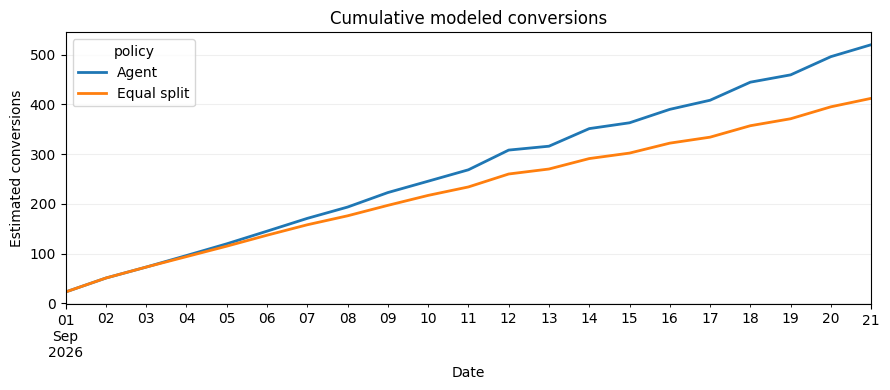

In [29]:
joined = data.merge(decisions[["date", "channel", "budget"]], on=["date", "channel"])
results = []
for policy, budgets in [("Agent", joined.budget),
                        ("Equal split", pd.Series(DAILY_BUDGET / len(channels), index=joined.index))]:
    scale = budgets / joined.spend
    estimated = joined[["date", "channel"]].copy()
    estimated["policy"] = policy
    estimated["budget"] = budgets
    for metric in ("impressions", "clicks", "conversions"):
        estimated[metric] = joined[metric] * scale
    results.append(estimated)

detail = pd.concat(results, ignore_index=True)
comparison = detail.groupby("policy")[["budget", "impressions", "clicks", "conversions"]].sum()
comparison["ctr"] = comparison.clicks / comparison.impressions
comparison["cvr"] = comparison.conversions / comparison.clicks
comparison["cpa"] = comparison.budget / comparison.conversions
print("\nEqual-spend comparison (modeled, assuming outcomes scale linearly with spend):")
print(comparison.round(3).to_string())

daily = detail.groupby(["date", "policy"]).conversions.sum().unstack()
ax = daily.cumsum().plot(figsize=(9, 4), linewidth=2)
ax.set(title="Cumulative modeled conversions", xlabel="Date", ylabel="Estimated conversions")
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

decisions.to_csv("ad_agent_decision_log.csv", index=False)
comparison.to_csv("ad_agent_evaluation.csv")